In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [29]:
df = pd.read_csv('./data/titanic.csv')
df.sample(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
845,846,0,3,"Abbing, Mr. Anthony",male,42.0,0,0,C.A. 5547,7.55,NaN,S
209,210,1,1,"Blank, Mr. Henry",male,40.0,0,0,112277,31.00,A31,C


In [33]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [34]:
missing_values_percentage = df.isnull().mean() * 100
missing_values_percentage = missing_values_percentage.round(2).sort_values(ascending=False)
print(missing_values_percentage)

Cabin          77.10
Age            19.87
Embarked        0.22
PassengerId     0.00
Name            0.00
Pclass          0.00
Survived        0.00
Sex             0.00
Parch           0.00
SibSp           0.00
Fare            0.00
Ticket          0.00
dtype: float64


<BarContainer object of 12 artists>

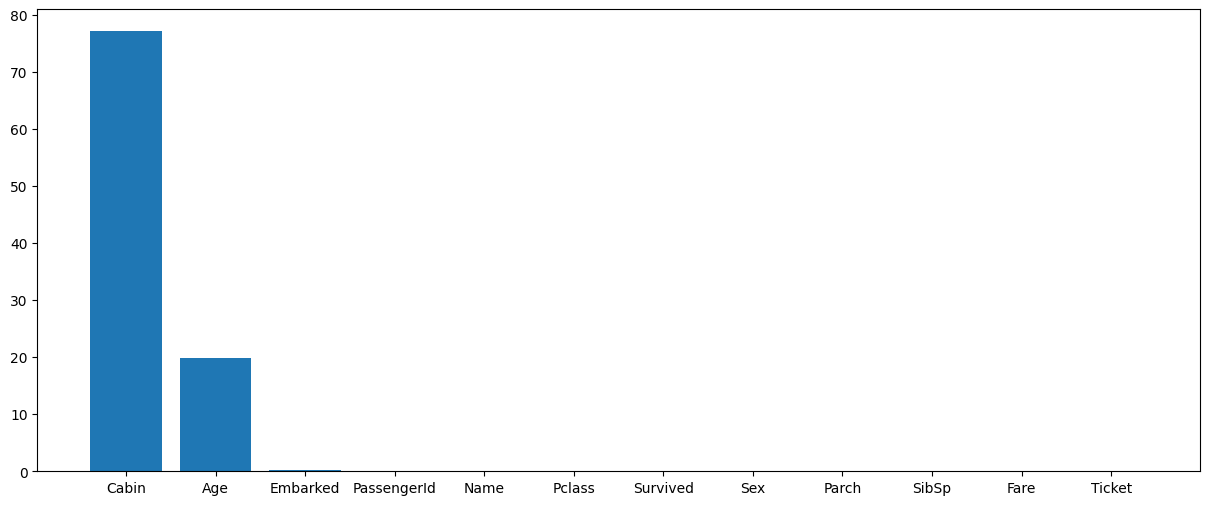

In [35]:
plt.figure(figsize=(15, 6))
plt.bar(x = missing_values_percentage.index, height = missing_values_percentage.values)


In [36]:
df.drop(columns="Cabin", inplace=True)

In [37]:
#Calcular la mediana de la columna Age
median_age = df['Age'].median()

#Imputar (o generar) los valores nulos con la mediana
df.Age = df['Age'].fillna(median_age, inplace=True)

/tmp/ipykernel_1246/3991293436.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df.Age = df['Age'].fillna(median_age, inplace=True)


In [38]:
df.Age.isna().sum()

np.int64(0)

In [39]:
df['Embarked'].mode()

0    S
Name: Embarked, dtype: str

In [40]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [41]:
df.isnull().sum().sort_values(ascending=False) / len(df) * 100

PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Embarked       0.0
dtype: float64

In [42]:
round(df.isnull().sum().sort_values(ascending=False) / len(df) * 100, 2)

PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Embarked       0.0
dtype: float64

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df.drop('Name', axis = 1, inplace = True)
df.drop('Ticket', axis = 1, inplace = True)
df.drop('PassengerId', axis = 1, inplace = True)

In [45]:
print(f'Después de limpiar df: {df.shape[0]} filas y {df.shape[1]} columnas')

Después de limpiar df: 891 filas y 8 columnas


In [14]:
df.to_csv('./data/titanic_clean.csv', index=False)